# Proyek Analisis Data (Analisis Pola Penyewaan Sepeda Berdasarkan Waktu, Hari Kerja, Cuaca, dan Musim): Bike Sharing Dataset
- **Nama:** Ni Putu Candradevi Davantari
- **Email:** davantari.24035@student.unud.ac.id
- **ID Dicoding:** DS014B6X1374

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

**Pertanyaan 1:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam antara hari kerja (*working day*) dan hari non-kerja (*weekend*/*holiday*) selama periode 2011–2012, serta pada jam berapa permintaan penyewaan mencapai puncaknya?

Keterangan:
*   Specific: Fokus pada pola penyewaan berdasarkan jam dan jenis hari.
* Measurable: Mengukur rata-rata jumlah penyewaan (cnt).
* Action-oriented: Membantu menentukan waktu operasional dan ketersediaan sepeda.
* Relevant: Berhubungan langsung dengan pengelolaan layanan penyewaan.
* Time-bound: Tahun 2011–2012.

**Pertanyaan 2:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca (*weathersit*) dan musim (*season*) selama periode 2011–2012, serta kondisi mana yang berkaitan dengan tingkat permintaan tertinggi dan terendah?

Keterangan:
* Specific: Fokus pada cuaca dan musim.
* Measurable: Mengukur rata-rata dan total penyewaan.
* Action-oriented: Membantu pengelola menyesuaikan ketersediaan sepeda berdasarkan kondisi lingkungan.
* Relevant: Mendukung pengelolaan operasional.
* Time-bound: Tahun 2011–2012.

## Import Semua Packages/Library yang Digunakan

In [4]:
# Import library untuk manipulasi dan analisis data
import pandas as pd
import numpy as np

# Import library untuk visualisasi data
import matplotlib.pyplot as plt
import seaborn as sns

# Mengatur tampilan visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Mengatur agar seluruh kolom ditampilkan
pd.set_option('display.max_columns', None)

## Data Wrangling

### Gathering Data
Dataset yang digunakan adalah Bike Sharing Dataset yang berisi data penyewaan sepeda selama periode 2011–2012. Analisis menggunakan dua file, yaitu hour.csv yang mencatat penyewaan berdasarkan jam dan day.csv yang mencatat penyewaan berdasarkan hari.

#### Loading dataset

In [5]:
# Memuat dataset
df_hour = pd.read_csv("hour.csv", parse_dates=["dteday"])
df_day = pd.read_csv("day.csv", parse_dates=["dteday"])

# Menampilkan lima data pertama
print("Dataset penyewaan per jam:")
display(df_hour.head())

print("Dataset penyewaan per hari:")
display(df_day.head())

# Menampilkan ukuran dataset
print("Ukuran dataset per jam:", df_hour.shape)
print("Ukuran dataset per hari:", df_day.shape)

Dataset penyewaan per jam:


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Dataset penyewaan per hari:


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


Ukuran dataset per jam: (17379, 17)
Ukuran dataset per hari: (731, 16)


**Insight:**

Berdasarkan proses pengumpulan data, diperoleh beberapa informasi awal sebagai berikut:
1. Dataset yang digunakan adalah Bike Sharing Dataset, yaitu dataset yang berisi informasi mengenai aktivitas penyewaan sepeda selama periode tahun 2011 hingga 2012.
2. Dataset terdiri dari dua file utama, yaitu hour.csv dan day.csv. Kedua file memiliki tingkat granularitas data yang berbeda.
3. File hour.csv memiliki 17.379 baris dan 17 kolom. Dataset ini mencatat jumlah penyewaan sepeda berdasarkan jam sehingga dapat digunakan untuk menganalisis pola permintaan penyewaan dalam satu hari.
4. File day.csv memiliki 731 baris dan 16 kolom. Dataset ini mencatat jumlah penyewaan berdasarkan hari sehingga dapat digunakan untuk melihat pola penyewaan dalam jangka waktu harian.
5. Kedua dataset memiliki informasi terkait waktu, musim, kondisi cuaca, serta jumlah penyewaan sepeda. Informasi tersebut dapat dimanfaatkan untuk menjawab pertanyaan bisnis yang telah dirumuskan.
6. Terdapat informasi jumlah penyewaan oleh pengguna kasual (casual) dan pengguna terdaftar (registered), serta total penyewaan (cnt). Informasi ini memungkinkan analisis karakteristik pengguna sepeda.

Dengan karakteristik tersebut, Bike Sharing Dataset dinilai sesuai untuk menganalisis hubungan pola penyewaan sepeda dengan waktu, hari kerja, musim, dan kondisi cuaca.

### Assessing Data

#### Identifying data problem

In [6]:
# Memeriksa struktur dan kualitas dataset

datasets = {
    'Hourly Dataset': df_hour,
    'Daily Dataset': df_day
}

for name, df in datasets.items():
    print(f'\n{"="*50}')
    print(f'ASSESSING {name.upper()}')
    print(f'{"="*50}')

    # 1. Memeriksa struktur dan tipe data
    print('\n1. Informasi Dataset:')
    print(f'Jumlah baris dan kolom: {df.shape}')
    print(df.dtypes)

    # 2. Memeriksa missing values
    print('\n2. Missing Values:')
    print(df.isnull().sum())

    # 3. Memeriksa duplicate data
    print('\n3. Duplicate Data:')
    print(f'Jumlah duplikasi: {df.duplicated().sum()}')

    # 4. Memeriksa invalid values pada kolom kategorikal
    print('\n4. Invalid Values pada Kolom Kategorikal:')

    valid_categories = {
        'season': [1, 2, 3, 4],
        'mnth': list(range(1, 13)),
        'weekday': list(range(7)),
        'weathersit': [1, 2, 3, 4],
        'workingday': [0, 1],
        'holiday': [0, 1],
        'yr': [0, 1]
    }

    if 'hr' in df.columns:
        valid_categories['hr'] = list(range(24))

    for col, valid_values in valid_categories.items():
        invalid_count = (~df[col].isin(valid_values)).sum()
        print(f'{col}: {invalid_count} nilai tidak valid')

    # 5. Memeriksa nilai negatif pada kolom numerik penting
    print('\n5. Nilai Negatif:')
    numerical_columns = [
        'temp', 'atemp', 'hum', 'windspeed',
        'casual', 'registered', 'cnt'
    ]

    for col in numerical_columns:
        negative_count = (df[col] < 0).sum()
        print(f'{col}: {negative_count} nilai negatif')

    # 6. Memeriksa rentang nilai kolom lingkungan
    print('\n6. Rentang Nilai Kolom Lingkungan:')
    for col in ['temp', 'atemp', 'hum', 'windspeed']:
        invalid_range = ((df[col] < 0) | (df[col] > 1)).sum()
        print(f'{col}: {invalid_range} nilai di luar rentang 0–1')

    # 7. Memeriksa konsistensi jumlah penyewaan
    print('\n7. Konsistensi Jumlah Penyewaan:')
    consistency = (
        df['casual'] + df['registered'] == df['cnt']
    ).all()
    print(f'casual + registered = cnt: {consistency}')

    # 8. Memeriksa validitas format tanggal
    print('\n8. Validitas Tanggal:')
    invalid_dates = pd.to_datetime(
        df['dteday'], errors='coerce'
    ).isna().sum()
    print(f'Jumlah tanggal tidak valid: {invalid_dates}')

    # 9. Statistik deskriptif
    print('\n9. Statistik Deskriptif:')
    print(df.describe())


ASSESSING HOURLY DATASET

1. Informasi Dataset:
Jumlah baris dan kolom: (17379, 17)
instant                int64
dteday        datetime64[ns]
season                 int64
yr                     int64
mnth                   int64
hr                     int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object

2. Missing Values:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

3. Duplicate Data:
Jumlah duplikasi: 0

4. Invalid Values pada Kolom Kategorikal:
season: 0 nilai tida

**Steps to Take:**

1. Missing Values: Tidak diperlukan penanganan karena kedua dataset tidak memiliki missing values.
2. Duplicate Data: Tidak diperlukan penghapusan data duplikat karena tidak ditemukan baris yang terduplikasi.
3. Invalid Categorical Values: Tidak diperlukan perbaikan karena seluruh nilai pada kolom kategorikal telah sesuai dengan rentang nilai yang ditentukan.
4. Invalid Numerical Values: Tidak diperlukan penanganan karena tidak ditemukan nilai negatif maupun nilai di luar rentang 0–1 pada kolom lingkungan.
5. Date Format: Kolom `dteday` sudah menggunakan tipe data datetime sehingga tidak memerlukan konversi tambahan.
6. Data Consistency: Tidak diperlukan perbaikan karena jumlah penyewaan pada kolom `casual` dan `registered` telah sesuai dengan total penyewaan pada kolom `cnt`.
7. Data Validation: Dataset dapat dilanjutkan ke tahap berikutnya karena seluruh pemeriksaan kualitas data menunjukkan hasil yang sesuai.

**Insight:**

1. Hourly Dataset memiliki 17.379 baris dan 17 kolom, sedangkan Daily Dataset memiliki 731 baris dan 16 kolom.
2. Kedua dataset tidak memiliki missing values maupun duplicate data, sehingga seluruh data dapat dipertahankan.
3. Seluruh nilai pada kolom kategorikal berada dalam rentang yang valid, dan tidak ditemukan nilai negatif maupun nilai di luar rentang 0–1 pada kolom lingkungan.
4. Kolom `dteday` pada kedua dataset sudah memiliki tipe data datetime dan tidak ditemukan tanggal yang tidak valid.
5. Konsistensi jumlah penyewaan telah terpenuhi, ditunjukkan oleh hasil validasi `casual + registered = cnt` yang bernilai True pada kedua dataset.
6. Secara keseluruhan, kedua dataset memiliki kualitas data yang baik berdasarkan pemeriksaan yang dilakukan dan dapat digunakan untuk analisis lebih lanjut.

### Cleaning Data

#### Fixing data problem

In [7]:

# 1. Membuat salinan dataset
df_hour_clean = df_hour.copy()
df_day_clean = df_day.copy()

# 2. Memastikan format kolom tanggal
df_hour_clean['dteday'] = pd.to_datetime(df_hour_clean['dteday'])
df_day_clean['dteday'] = pd.to_datetime(df_day_clean['dteday'])

# 3. Menghapus data duplikat
df_hour_clean.drop_duplicates(inplace=True)
df_day_clean.drop_duplicates(inplace=True)

# 4. Memeriksa missing values
print("Missing Values Setelah Cleaning:")
print("Hourly Dataset:", df_hour_clean.isnull().sum().sum())
print("Daily Dataset:", df_day_clean.isnull().sum().sum())

# 5. Memeriksa data duplikat
print("\nDuplikat Setelah Cleaning:")
print("Hourly Dataset:", df_hour_clean.duplicated().sum())
print("Daily Dataset:", df_day_clean.duplicated().sum())

# 6. Memvalidasi jumlah penyewaan sepeda
print("\nValidasi Jumlah Penyewaan:")
print("Hourly Dataset:",
      (df_hour_clean['casual'] + df_hour_clean['registered'] == df_hour_clean['cnt']).all())

print("Daily Dataset:",
      (df_day_clean['casual'] + df_day_clean['registered'] == df_day_clean['cnt']).all())

# 7. Menampilkan ukuran dataset setelah cleaning
print("\nUkuran Dataset Setelah Cleaning:")
print("Hourly Dataset:", df_hour_clean.shape)
print("Daily Dataset:", df_day_clean.shape)

Missing Values Setelah Cleaning:
Hourly Dataset: 0
Daily Dataset: 0

Duplikat Setelah Cleaning:
Hourly Dataset: 0
Daily Dataset: 0

Validasi Jumlah Penyewaan:
Hourly Dataset: True
Daily Dataset: True

Ukuran Dataset Setelah Cleaning:
Hourly Dataset: (17379, 17)
Daily Dataset: (731, 16)


**Insight:**

1. Dataset hourly dan daily tidak memiliki missing values maupun data duplikat, sehingga tidak diperlukan penghapusan atau penanganan data yang hilang.
2. Kolom `dteday` pada kedua dataset telah dipastikan menggunakan format datetime untuk mendukung analisis berdasarkan waktu.
3. Hasil validasi menunjukkan bahwa nilai `cnt` pada kedua dataset konsisten dengan penjumlahan `casual` dan `registered`, yang ditunjukkan oleh hasil validasi True.
4. Jumlah data setelah proses cleaning tidak mengalami perubahan, yaitu 17.379 baris dan 17 kolom pada dataset hourly serta 731 baris dan 16 kolom pada dataset daily.


## Exploratory Data Analysis (EDA)

### Explore Data

In [8]:

# ==========================================
# EXPLORATORY DATA ANALYSIS (EDA)
# ==========================================

# PERTANYAAN 1:
# Pola penyewaan berdasarkan hari kerja dan jam

print("=" * 60)
print("EDA PERTANYAAN 1")
print("=" * 60)

# Membandingkan rata-rata penyewaan pada hari kerja dan non-kerja
workingday_analysis = df_hour_clean.groupby('workingday')['cnt'].agg(
    rata_rata='mean',
    total='sum',
    jumlah_data='count'
).reset_index()

workingday_analysis['jenis_hari'] = workingday_analysis['workingday'].map({
    0: 'Hari Non-Kerja',
    1: 'Hari Kerja'
})

print("\nRata-rata Penyewaan Berdasarkan Jenis Hari:")
print(workingday_analysis[['jenis_hari', 'rata_rata', 'total', 'jumlah_data']].round(2))

# Mencari rata-rata penyewaan berdasarkan jam dan jenis hari
hourly_analysis = df_hour_clean.groupby(
    ['workingday', 'hr']
)['cnt'].mean().reset_index()

hourly_analysis['jenis_hari'] = hourly_analysis['workingday'].map({
    0: 'Hari Non-Kerja',
    1: 'Hari Kerja'
})

# Menentukan jam dengan rata-rata penyewaan tertinggi
peak_hour = hourly_analysis.loc[
    hourly_analysis.groupby('workingday')['cnt'].idxmax()
]

print("\nJam dengan Rata-rata Penyewaan Tertinggi:")
print(peak_hour[['jenis_hari', 'hr', 'cnt']].round(2))


# PERTANYAAN 2:
# Pola penyewaan berdasarkan cuaca dan musim

print("\n" + "=" * 60)
print("EDA PERTANYAAN 2")
print("=" * 60)

# Analisis berdasarkan kondisi cuaca
weather_analysis = df_day_clean.groupby('weathersit')['cnt'].agg(
    rata_rata='mean',
    total='sum',
    jumlah_data='count'
).reset_index()

weather_analysis['kondisi_cuaca'] = weather_analysis['weathersit'].map({
    1: 'Cerah / Sedikit Berawan',
    2: 'Berkabut / Berawan',
    3: 'Hujan Ringan / Salju Ringan',
    4: 'Hujan Lebat / Salju Lebat'
})

print("\nPenyewaan Berdasarkan Kondisi Cuaca:")
print(weather_analysis[
    ['kondisi_cuaca', 'rata_rata', 'total', 'jumlah_data']
].round(2))

# Analisis berdasarkan musim
season_analysis = df_day_clean.groupby('season')['cnt'].agg(
    rata_rata='mean',
    total='sum',
    jumlah_data='count'
).reset_index()

season_analysis['musim'] = season_analysis['season'].map({
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
})

print("\nPenyewaan Berdasarkan Musim:")
print(season_analysis[
    ['musim', 'rata_rata', 'total', 'jumlah_data']
].round(2))

# Menentukan kondisi cuaca dan musim dengan rata-rata tertinggi dan terendah
print("\nKondisi dengan Rata-rata Penyewaan Tertinggi dan Terendah:")

print("Cuaca tertinggi:",
      weather_analysis.loc[weather_analysis['rata_rata'].idxmax(), 'kondisi_cuaca'])

print("Cuaca terendah:",
      weather_analysis.loc[weather_analysis['rata_rata'].idxmin(), 'kondisi_cuaca'])

print("Musim tertinggi:",
      season_analysis.loc[season_analysis['rata_rata'].idxmax(), 'musim'])

print("Musim terendah:",
      season_analysis.loc[season_analysis['rata_rata'].idxmin(), 'musim'])

EDA PERTANYAAN 1

Rata-rata Penyewaan Berdasarkan Jenis Hari:
       jenis_hari  rata_rata    total  jumlah_data
0  Hari Non-Kerja     181.41  1000269         5514
1      Hari Kerja     193.21  2292410        11865

Jam dengan Rata-rata Penyewaan Tertinggi:
        jenis_hari  hr     cnt
13  Hari Non-Kerja  13  372.73
41      Hari Kerja  17  525.29

EDA PERTANYAAN 2

Penyewaan Berdasarkan Kondisi Cuaca:
                 kondisi_cuaca  rata_rata    total  jumlah_data
0      Cerah / Sedikit Berawan    4876.79  2257952          463
1           Berkabut / Berawan    4035.86   996858          247
2  Hujan Ringan / Salju Ringan    1803.29    37869           21

Penyewaan Berdasarkan Musim:
    musim  rata_rata    total  jumlah_data
0  Spring    2604.13   471348          181
1  Summer    4992.33   918589          184
2    Fall    5644.30  1061129          188
3  Winter    4728.16   841613          178

Kondisi dengan Rata-rata Penyewaan Tertinggi dan Terendah:
Cuaca tertinggi: Cerah / Sedikit

**Insight:**
1. Pola Penyewaan Berdasarkan Hari Kerja dan Hari Non-Kerja

Berdasarkan hasil eksplorasi, rata-rata penyewaan sepeda pada hari kerja mencapai 193,21 penyewaan per jam, sedikit lebih tinggi dibandingkan hari non-kerja sebesar 181,41 penyewaan per jam. Jika dilihat berdasarkan jam, waktu dengan rata-rata penyewaan tertinggi pada hari kerja terjadi pukul 17.00 dengan rata-rata 525,29 penyewaan, sedangkan pada hari non-kerja terjadi pukul 13.00 dengan rata-rata 372,73 penyewaan. Perbedaan ini menunjukkan bahwa pola penggunaan sepeda memiliki waktu puncak yang berbeda antara hari kerja dan hari non-kerja.

2. Pola Penyewaan Berdasarkan Kondisi Cuaca dan Musim

Hasil eksplorasi menunjukkan bahwa rata-rata penyewaan sepeda tertinggi berdasarkan kondisi cuaca terjadi pada cuaca cerah atau sedikit berawan, yaitu sebesar 4.876,79 penyewaan per hari. Sementara itu, rata-rata terendah ditemukan pada kondisi hujan ringan atau salju ringan sebesar 1.803,29 penyewaan per hari. Namun, kategori tersebut hanya memiliki 21 observasi dan kategori cuaca nomor 4 tidak ditemukan dalam dataset harian. Berdasarkan musim, Fall memiliki rata-rata penyewaan tertinggi sebesar 5.644,30 penyewaan per hari, sedangkan Spring memiliki rata-rata terendah sebesar 2.604,13 penyewaan per hari. Hasil ini menunjukkan adanya hubungan antara kondisi cuaca dan musim dengan perubahan jumlah penyewaan sepeda selama periode pengamatan.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Bagaimana perbedaan rata-rata jumlah penyewaan sepeda per jam antara hari kerja dan hari non-kerja selama periode 2011–2012, serta pada jam berapa permintaan penyewaan mencapai puncaknya?

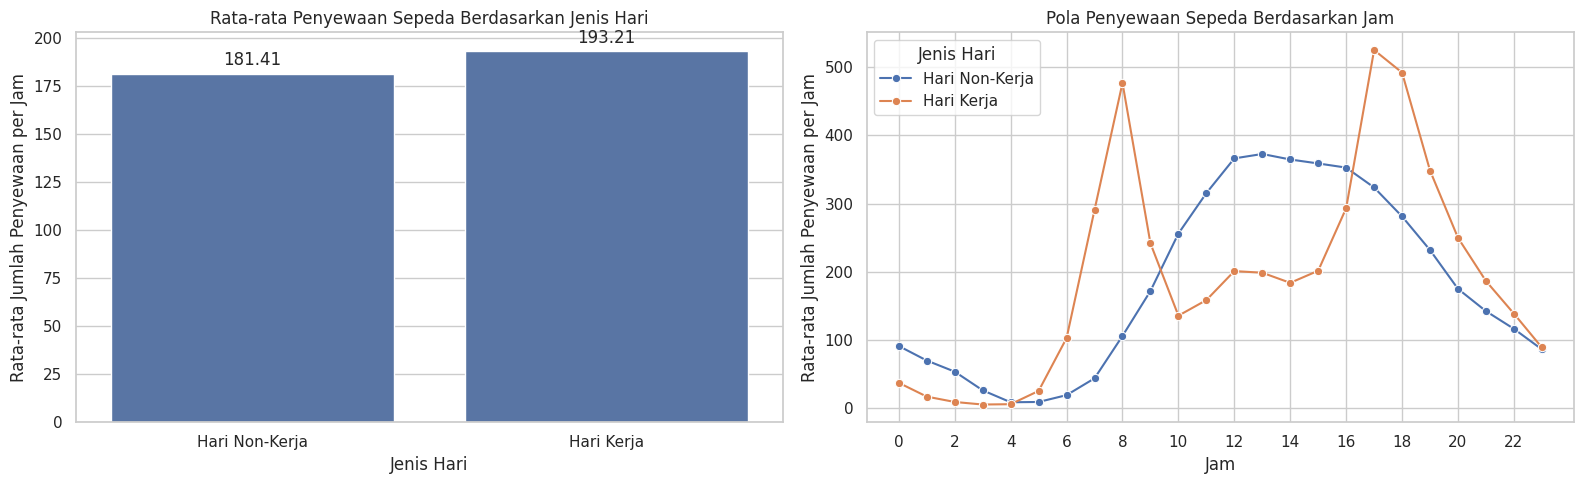

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Menyiapkan label jenis hari
workingday_analysis['jenis_hari'] = workingday_analysis['workingday'].map({
    0: 'Hari Non-Kerja',
    1: 'Hari Kerja'
})

hourly_analysis['jenis_hari'] = hourly_analysis['workingday'].map({
    0: 'Hari Non-Kerja',
    1: 'Hari Kerja'
})

# Membuat area visualisasi
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Grafik 1: Rata-rata penyewaan berdasarkan jenis hari
sns.barplot(
    data=workingday_analysis,
    x='jenis_hari',
    y='rata_rata',
    ax=axes[0]
)

axes[0].set_title('Rata-rata Penyewaan Sepeda Berdasarkan Jenis Hari')
axes[0].set_xlabel('Jenis Hari')
axes[0].set_ylabel('Rata-rata Jumlah Penyewaan per Jam')

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f', padding=3)

# Grafik 2: Rata-rata penyewaan berdasarkan jam
sns.lineplot(
    data=hourly_analysis,
    x='hr',
    y='cnt',
    hue='jenis_hari',
    marker='o',
    ax=axes[1]
)

axes[1].set_title('Pola Penyewaan Sepeda Berdasarkan Jam')
axes[1].set_xlabel('Jam')
axes[1].set_ylabel('Rata-rata Jumlah Penyewaan per Jam')
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend(title='Jenis Hari')

plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca dan musim selama periode 2011–2012, serta kondisi mana yang berkaitan dengan tingkat permintaan tertinggi dan terendah?

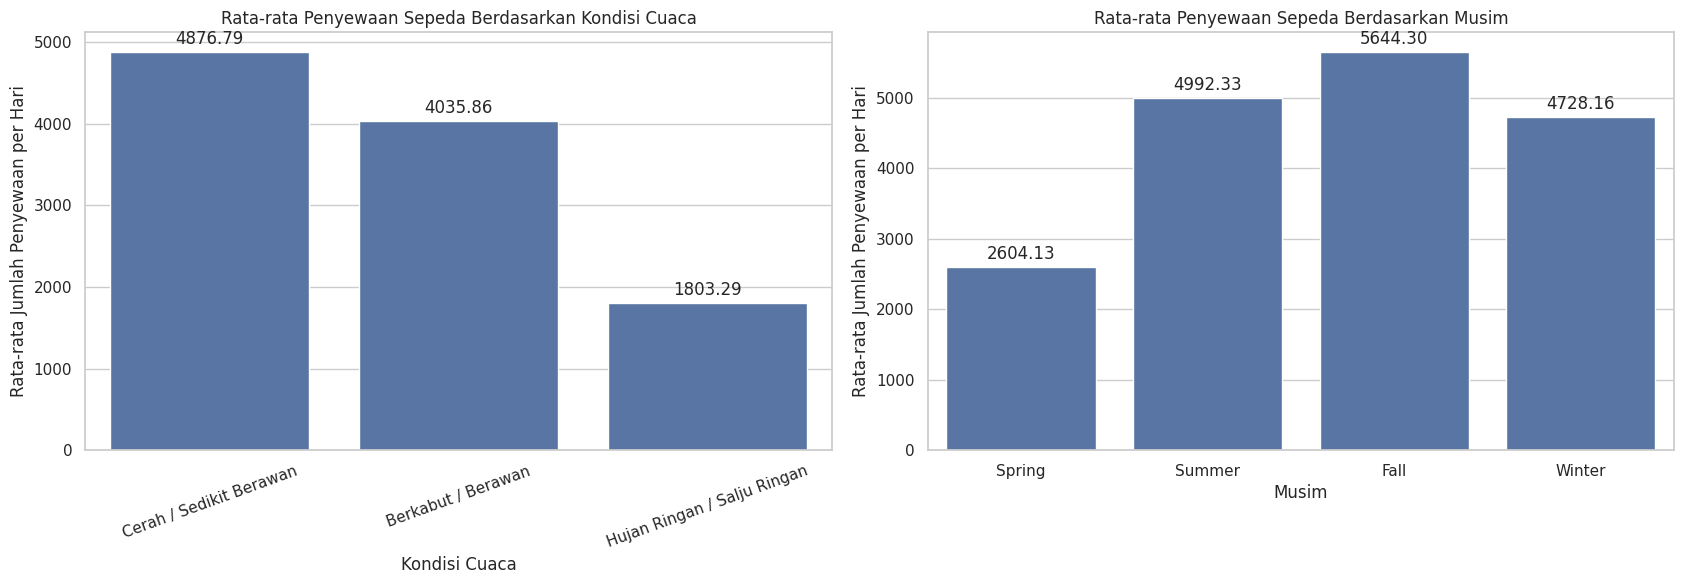

In [10]:
# Menyiapkan label kondisi cuaca dan musim
weather_analysis['kondisi_cuaca'] = weather_analysis['weathersit'].map({
    1: 'Cerah / Sedikit Berawan',
    2: 'Berkabut / Berawan',
    3: 'Hujan Ringan / Salju Ringan',
    4: 'Hujan Lebat / Salju Lebat'
})

season_analysis['musim'] = season_analysis['season'].map({
    1: 'Spring',
    2: 'Summer',
    3: 'Fall',
    4: 'Winter'
})

# Membuat area visualisasi
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

# Grafik 1: Rata-rata penyewaan berdasarkan cuaca
sns.barplot(
    data=weather_analysis,
    x='kondisi_cuaca',
    y='rata_rata',
    ax=axes[0]
)

axes[0].set_title('Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca')
axes[0].set_xlabel('Kondisi Cuaca')
axes[0].set_ylabel('Rata-rata Jumlah Penyewaan per Hari')
axes[0].tick_params(axis='x', rotation=20)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f', padding=3)

# Grafik 2: Rata-rata penyewaan berdasarkan musim
sns.barplot(
    data=season_analysis,
    x='musim',
    y='rata_rata',
    order=['Spring', 'Summer', 'Fall', 'Winter'],
    ax=axes[1]
)

axes[1].set_title('Rata-rata Penyewaan Sepeda Berdasarkan Musim')
axes[1].set_xlabel('Musim')
axes[1].set_ylabel('Rata-rata Jumlah Penyewaan per Hari')

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

**Insight:**

**1. Pola Penyewaan Berdasarkan Hari Kerja dan Hari Non-Kerja**

Berdasarkan visualisasi, rata-rata penyewaan sepeda pada hari kerja sebesar 193,21 penyewaan per jam, sedikit lebih tinggi dibandingkan hari non-kerja sebesar 181,41 penyewaan per jam. Namun, pola waktu penyewaan menunjukkan perbedaan yang cukup jelas. Pada hari kerja, permintaan tertinggi terjadi pukul 17.00 dengan rata-rata 525,29 penyewaan, sedangkan pada hari non-kerja terjadi pukul 13.00 dengan rata-rata 372,73 penyewaan. Hal ini menunjukkan bahwa waktu puncak penyewaan berbeda antara hari kerja dan hari non-kerja.

**2. Pola Penyewaan Berdasarkan Kondisi Cuaca dan Musim**

Berdasarkan kondisi cuaca, rata-rata penyewaan tertinggi terjadi saat cuaca cerah atau sedikit berawan, yaitu 4.876,79 penyewaan per hari. Sementara itu, rata-rata terendah ditemukan pada kondisi hujan ringan atau salju ringan sebesar 1.803,29 penyewaan per hari. Berdasarkan musim, Fall memiliki rata-rata penyewaan tertinggi sebesar 5.644,30 penyewaan per hari, sedangkan Spring memiliki rata-rata terendah sebesar 2.604,13 penyewaan per hari. Hasil visualisasi menunjukkan adanya perbedaan pola penyewaan berdasarkan kondisi cuaca dan musim.

## Analisis Lanjutan (Opsional)

In [12]:
# ANALISIS LANJUTAN

# 1. Perbandingan penyewaan hari kerja dan non-kerja
avg_non_working = workingday_analysis.loc[
    workingday_analysis['workingday'] == 0, 'rata_rata'
].iloc[0]

avg_working = workingday_analysis.loc[
    workingday_analysis['workingday'] == 1, 'rata_rata'
].iloc[0]

selisih_hari = avg_working - avg_non_working
persentase_hari = (selisih_hari / avg_non_working) * 100


# 2. Perbandingan penyewaan berdasarkan cuaca
avg_weather_high = weather_analysis['rata_rata'].max()
avg_weather_low = weather_analysis['rata_rata'].min()

selisih_cuaca = avg_weather_high - avg_weather_low
persentase_cuaca = (selisih_cuaca / avg_weather_low) * 100


# 3. Perbandingan penyewaan berdasarkan musim
avg_season_high = season_analysis['rata_rata'].max()
avg_season_low = season_analysis['rata_rata'].min()

selisih_musim = avg_season_high - avg_season_low
persentase_musim = (selisih_musim / avg_season_low) * 100


# Menampilkan hasil perbandingan
print("PERBANDINGAN RATA-RATA PENYEWAAN")
print("=" * 50)

print("\nHari Kerja dan Non-Kerja:")
print(f"Selisih rata-rata: {selisih_hari:.2f} penyewaan per jam")
print(f"Persentase perbedaan: {persentase_hari:.2f}%")

print("\nKondisi Cuaca:")
print(f"Selisih rata-rata: {selisih_cuaca:.2f} penyewaan per hari")
print(f"Persentase perbedaan: {persentase_cuaca:.2f}%")

print("\nMusim:")
print(f"Selisih rata-rata: {selisih_musim:.2f} penyewaan per hari")
print(f"Persentase perbedaan: {persentase_musim:.2f}%")


# 4. Analisis korelasi Spearman
# Tujuan: mengetahui arah dan kekuatan hubungan monotonik
# antara variabel lingkungan dengan jumlah penyewaan sepeda.
# Spearman menggunakan peringkat data dan tidak mengharuskan
# hubungan antarvariabel berbentuk linear.

kolom_korelasi = ['temp', 'atemp', 'hum', 'windspeed', 'cnt']

spearman_corr = df_day_clean[kolom_korelasi].corr(
    method='spearman'
)

korelasi_penyewaan = spearman_corr['cnt'].drop('cnt').sort_values(
    ascending=False
)

print("\n" + "=" * 50)
print("KORELASI SPEARMAN TERHADAP JUMLAH PENYEWAAN")
print("=" * 50)

print(korelasi_penyewaan.round(3))


# 5. Analisis Binning Suhu
# Tujuan: mengelompokkan suhu ke dalam empat rentang
# untuk membandingkan rata-rata penyewaan pada setiap kelompok.

df_day_clean['kategori_suhu'] = pd.cut(
    df_day_clean['temp'],
    bins=4,
    labels=[
        'Suhu rendah',
        'Suhu sedang-rendah',
        'Suhu sedang-tinggi',
        'Suhu tinggi'
    ],
    include_lowest=True
)

binning_suhu = df_day_clean.groupby(
    'kategori_suhu',
    observed=False
).agg(
    rata_rata_penyewaan=('cnt', 'mean'),
    total_penyewaan=('cnt', 'sum'),
    jumlah_hari=('cnt', 'count')
).round(2)

print("\n" + "=" * 50)
print("ANALISIS BINNING SUHU TERHADAP JUMLAH PENYEWAAN")
print("=" * 50)

print(binning_suhu)

PERBANDINGAN RATA-RATA PENYEWAAN

Hari Kerja dan Non-Kerja:
Selisih rata-rata: 11.80 penyewaan per jam
Persentase perbedaan: 6.51%

Kondisi Cuaca:
Selisih rata-rata: 3073.50 penyewaan per hari
Persentase perbedaan: 170.44%

Musim:
Selisih rata-rata: 3040.17 penyewaan per hari
Persentase perbedaan: 116.74%

KORELASI SPEARMAN TERHADAP JUMLAH PENYEWAAN
atemp        0.623
temp         0.622
hum         -0.098
windspeed   -0.217
Name: cnt, dtype: float64

ANALISIS BINNING SUHU TERHADAP JUMLAH PENYEWAAN
                    rata_rata_penyewaan  total_penyewaan  jumlah_hari
kategori_suhu                                                        
Suhu rendah                     1819.70           132838           73
Suhu sedang-rendah              3596.72           924358          257
Suhu sedang-tinggi              5547.67          1264869          228
Suhu tinggi                     5610.49           970614          173


**Insight:**

Hasil analisis lanjutan menunjukkan bahwa rata-rata penyewaan sepeda pada hari kerja lebih tinggi sebesar 11,80 penyewaan per jam atau sekitar 6,51% dibandingkan hari non-kerja.

Pada kondisi cuaca, terdapat selisih rata-rata sebesar 3.073,50 penyewaan per hari antara kondisi cerah atau sedikit berawan dengan kondisi hujan ringan atau salju ringan. Rata-rata penyewaan pada kondisi cuaca cerah atau sedikit berawan sekitar 170,44% lebih tinggi dibandingkan kondisi hujan ringan atau salju ringan.

Sementara itu, berdasarkan musim, terdapat selisih rata-rata sebesar 3.040,17 penyewaan per hari antara musim Fall dan Spring. Rata-rata penyewaan pada musim Fall sekitar 116,74% lebih tinggi dibandingkan musim Spring.

Analisis korelasi Spearman digunakan untuk mengetahui arah dan kekuatan hubungan antara variabel lingkungan dengan jumlah penyewaan sepeda. Hasilnya menunjukkan bahwa suhu yang dirasakan (atemp) memiliki hubungan positif paling kuat dengan jumlah penyewaan, dengan nilai korelasi sebesar 0,623. Suhu (temp) juga menunjukkan hubungan positif sebesar 0,622. Sementara itu, kelembapan (hum) memiliki hubungan negatif yang sangat lemah sebesar -0,098, sedangkan kecepatan angin (windspeed) memiliki hubungan negatif sebesar -0,217.

Selain itu, analisis binning suhu dilakukan dengan membagi suhu ke dalam empat kelompok untuk melihat perbedaan rata-rata penyewaan pada setiap rentang suhu. Hasilnya menunjukkan bahwa kelompok suhu tinggi memiliki rata-rata penyewaan tertinggi sebesar 5.610,49 penyewaan per hari, diikuti oleh kelompok suhu sedang-tinggi sebesar 5.547,67. Sementara itu, kelompok suhu rendah memiliki rata-rata penyewaan terendah sebesar 1.819,70 penyewaan per hari. Hasil ini memperlihatkan bahwa kelompok suhu yang lebih tinggi cenderung memiliki rata-rata penyewaan yang lebih besar dibandingkan kelompok suhu rendah.

Secara keseluruhan, hasil analisis menunjukkan bahwa perbedaan rata-rata penyewaan paling besar secara persentase ditemukan pada kategori kondisi cuaca, diikuti oleh musim. Analisis Spearman dan binning juga memperlihatkan adanya keterkaitan antara suhu dan jumlah penyewaan sepeda. Dengan demikian, kondisi lingkungan, khususnya suhu dan cuaca, dapat menjadi salah satu pertimbangan dalam memahami pola permintaan penyewaan sepeda. Namun, hasil analisis ini tidak membuktikan hubungan sebab-akibat.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Berdasarkan hasil analisis, rata-rata penyewaan sepeda pada hari kerja sebesar 193,21 penyewaan per jam, lebih tinggi dibandingkan hari non-kerja sebesar 181,41 penyewaan per jam. Meskipun perbedaannya tidak terlalu besar, pola waktu penyewaan menunjukkan perbedaan yang jelas. Pada hari kerja, permintaan tertinggi terjadi pukul 17.00, sedangkan pada hari non-kerja terjadi pukul 13.00. Dengan demikian, waktu puncak penyewaan sepeda berbeda berdasarkan jenis hari, yaitu cenderung pada sore hari saat hari kerja dan siang hari saat hari non-kerja.
- **Conclusion pertanyaan 2:** Berdasarkan hasil analisis, kondisi cuaca dan musim menunjukkan perbedaan rata-rata jumlah penyewaan sepeda. Cuaca cerah atau sedikit berawan memiliki rata-rata penyewaan tertinggi sebesar 4.876,79 penyewaan per hari, sedangkan hujan ringan atau salju ringan memiliki rata-rata terendah sebesar 1.803,29 penyewaan per hari di antara kategori yang tersedia. Berdasarkan musim, Fall memiliki rata-rata penyewaan tertinggi sebesar 5.644,30 penyewaan per hari, sedangkan Spring memiliki rata-rata terendah sebesar 2.604,13 penyewaan per hari. Analisis korelasi Spearman juga menunjukkan bahwa suhu dan suhu yang dirasakan memiliki hubungan positif yang cukup kuat dengan jumlah penyewaan. Dengan demikian, kondisi cuaca dan musim serta variabel suhu dapat menjadi pertimbangan dalam memahami perubahan permintaan penyewaan sepeda.

**Rekomendasi Action Item:**


- Menyesuaikan Ketersediaan Sepeda Berdasarkan Waktu: Penyedia layanan disarankan untuk memastikan ketersediaan sepeda lebih banyak pada pukul 17.00 saat hari kerja dan pukul 13.00 saat hari non-kerja. Penyesuaian ini dapat membantu mengantisipasi peningkatan permintaan pada waktu puncak penyewaan.

- Mengoptimalkan Persediaan Sepeda Berdasarkan Musim: Penyedia layanan dapat mempersiapkan ketersediaan sepeda dan kebutuhan operasional secara lebih optimal selama musim Fall karena musim tersebut memiliki rata-rata penyewaan tertinggi. Sementara itu, pada musim Spring, persediaan dapat disesuaikan dengan rata-rata permintaan yang lebih rendah.

- Mempertimbangkan Kondisi Cuaca dan Suhu: Penyedia layanan disarankan untuk memperhatikan kondisi cuaca dan suhu dalam merencanakan operasional. Hal ini didukung oleh hasil analisis yang menunjukkan bahwa kondisi cuaca cerah atau sedikit berawan memiliki rata-rata penyewaan lebih tinggi, serta suhu dan suhu yang dirasakan memiliki hubungan positif dengan jumlah penyewaan. Pada kondisi cuaca yang kurang mendukung, keamanan dan kenyamanan pengguna tetap perlu menjadi perhatian.

- Melakukan Pemantauan Permintaan Secara Berkala: Penyedia layanan disarankan untuk terus memantau pola penyewaan berdasarkan waktu, jenis hari, cuaca, musim, dan kondisi suhu. Pemantauan secara berkala dapat membantu penyedia layanan mengevaluasi perubahan permintaan dan menyesuaikan strategi operasional berdasarkan pola penyewaan yang ditemukan.